# Probas-Capstone : le seuil de percolation, un problème inverse bayésien

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jsboige/CoursIA/blob/main/MyIA.AI.Notebooks/Probas/Probas-Capstone-Percolation-Bayesienne-Python.ipynb)

**Navigation** : [Index de la série Probas](README.md) | Sous-série investie : [Applications/Percolation](Applications/Percolation/README.md)

**Série** : [Probas](README.md) — ce carnet est le **capstone de la série mère** : il consomme les cinq sous-séries (Fondations, Applications, DecisionTheory, Infer, PyMC) sur un seul problème, en réinvestissant des mesures **déjà committées** par la sous-série Percolation. La note de conception qui le fonde est rendue sur l'issue de finition de série #19297.

## Ce que ce notebook suppose

- **Fondations** : ce qu'est un échantillonneur MCMC et pourquoi Metropolis marche — [Probas-MCMC](Fondations/Probas-MCMC-Echantillonnage-Metropolis-Python.ipynb).
- **Applications/Percolation** : la physique du seuil (paramètre d'ordre $M/L^2$, exposants $\beta/\nu$, corrections de taille finie) — [Percolation-03b](Applications/Percolation/Percolation-03b-Critique-L128-L256.ipynb), [Percolation-03c](Applications/Percolation/Percolation-03c-Critique-L512.ipynb), [Percolation-04](Applications/Percolation/Percolation-04-Sharpness-Python.ipynb).
- **PyMC** : écrire et lire un modèle hiérarchique NUTS — [PyMC-12](PyMC/PyMC-12-Modeles-Hierarchiques.ipynb).
- **DecisionTheory** : la valeur de l'information — [DecPyMC-08](DecisionTheory/DecPyMC/DecPyMC-08-Actuariat-Capstone.ipynb) (geste de souscription) et le corpus [voi](DecisionTheory/voi/).
- **Infer** : l'idée du message passing — obtenir un posterior **sans** échantillonner — voir le [corpus jumeau](Infer/README.md).

Environnement : Python 3.13, `pymc` ≥ 5, `arviz`, `numpy`, `scipy`, `matplotlib`. Durée indicative : 45-60 min. Aucune nouvelle simulation de percolation : tout ce qui est mesuré ici était déjà dans le dépôt.

## 1. Le problème — une mesure sans intervalle

La sous-série [Percolation](Applications/Percolation/README.md) a mesuré, carnet après carnet, comment le paramètre d'ordre $M/L^2$ d'un réseau carré à liens ouverts franchit son seuil : des courbes de franchissement à trois tailles ($L = 128, 256, 512$, 32 graines chacune), un seuil apparent $p_c(L)$ par taille, un ajustement log-log qui rend $\beta/\nu = 0{,}1079$ contre la cible $5/48 \approx 0{,}1042$. Tout cela est **fréquentiste** : un point, un écart-type d'ajustement, pas de distribution.

Or la théorie a tranché ce cas précis : pour la percolation de **liens** sur $\mathbb{Z}^2$, $p_c = 1/2$ **exactement** (Kesten 1980). C'est une aubaine rare : un simulateur dont on connaît la réponse, donc un terrain où apprendre à quantifier l'incertitude **avant** de l'appliquer à un cas sans preuve (la percolation de **sites**, $p_c \approx 0{,}5927$, exercice 1).

Ce capstone retourne la question des carnets précédents :

> Non plus « quelle valeur de $p_c$ nos ajustements produisent-ils », mais **« que savent nos données, avec quelle incertitude : quelle est la distribution de $p_c$ sachant les mesures committées ? »**

C'est un problème **inverse** bayésien, et il consomme la série entière :

| Jambe | Réinvestit | Geste |
|---|---|---|
| Données | [Applications/Percolation](Applications/Percolation/README.md) | reprendre les mesures committées telles quelles |
| Échantillonnage | [Fondations/Probas-MCMC](Fondations/Probas-MCMC-Echantillonnage-Metropolis-Python.ipynb) | Metropolis à la main, puis NUTS |
| Modèle hiérarchique | [PyMC-12](PyMC/PyMC-12-Modeles-Hierarchiques.ipynb) | trois tailles, un seuil, des erreurs réelles |
| Décision | [DecisionTheory/voi](DecisionTheory/voi/) | faut-il payer une campagne $L = 1024$ ? |
| Message passing | [Infer](Infer/README.md) | le même posterior sans échantillonner |

In [1]:
import warnings

import numpy as np
import matplotlib.pyplot as plt
import scipy
import pymc as pm
import arviz as az

warnings.filterwarnings("ignore", category=FutureWarning)
print(f"numpy {np.__version__} | scipy {scipy.__version__} | pymc {pm.__version__} | arviz {az.__version__}")

# --- Mesures committes de la sous-serie Percolation (aucune nouvelle simulation) ---

# Percolation-03b, cellule exec 8 : seuil apparent p_c(L) par ajustement de courbe.
# L=8 etait hors plage ; L=512 n'a pas fait l'objet d'un seuil apparent.
L_pc = np.array([16, 32, 64, 128, 256], dtype=float)
pc_obs = np.array([0.4527, 0.4737, 0.4885, 0.4942, 0.4984])

# Percolation-03b cellule exec 3 + Percolation-03c cellule exec 3 :
# M/L^2 (moyenne +/- erreur standard sur 32 graines) a cinq pressions.
P_GRID = np.array([0.45, 0.48, 0.50, 0.52, 0.55])
courbes = {
    128: (np.array([0.0513, 0.2201, 0.6149, 0.8003, 0.8881]),
          np.array([0.0133, 0.1084, 0.1112, 0.0286, 0.0078])),
    256: (np.array([0.0177, 0.0916, 0.5352, 0.7951, 0.8884]),
          np.array([0.0045, 0.0408, 0.1229, 0.0175, 0.0043])),
    512: (np.array([0.0055, 0.0399, 0.5131, 0.7957, 0.8884]),
          np.array([0.0010, 0.0146, 0.0988, 0.0089, 0.0026])),
}

# Percolation-03b cellule exec 7 + Percolation-03c cellule exec 4 :
# parametre d'ordre a p = 0.50 pour sept tailles (fit beta/nu = 0.1079, cible 5/48).
L_M50 = np.array([8, 16, 32, 64, 128, 256, 512], dtype=float)
M50_obs = np.array([0.7939, 0.7347, 0.7158, 0.6363, 0.6149, 0.5352, 0.5131])

# Percolation-04 cellule exec 3 : cout d'une simulation (ms), par pression puis median.
ms_par_p = {
    64: [4, 4, 6, 4, 4, 4, 7, 4],
    128: [20, 20, 24, 23, 27, 24, 27, 30],
    256: [101, 126, 145, 130, 133, 140, 143, 147],
    512: [633],  # seule la pression p=0.50 est relevee a L=512 dans la sortie
}
L_cout = np.array(sorted(ms_par_p), dtype=float)
ms_sim = np.array([np.median(v) for v in (ms_par_p[k] for k in sorted(ms_par_p))])

# Valeurs theoriques (percolation de liens sur Z^2) : p_c = 1/2 (Kesten 1980), nu = 4/3.
PC_EXACT = 0.5
INV_NU_THEORIE = 0.75

print(f"Courbes de franchissement : {len(courbes)} tailles x {len(P_GRID)} pressions = "
      f"{len(courbes) * len(P_GRID)} points avec erreurs standard")
print(f"Cout median par simulation : " + ", ".join(f"L={int(L)}: {m:.0f} ms" for L, m in zip(L_cout, ms_sim)))

numpy 2.4.6 | scipy 1.17.1 | pymc 5.28.5 | arviz 0.23.4
Courbes de franchissement : 3 tailles x 5 pressions = 15 points avec erreurs standard
Cout median par simulation : L=64: 4 ms, L=128: 24 ms, L=256: 136 ms, L=512: 633 ms


## 2. Ce que la série a déjà payé — et pourquoi on le réutilise

Les nombres de la cellule précédente ne sont pas des exemples : ce sont des **sorties committées** de la sous-série. Chaque point de $M/L^2$ à $L=512$ a coûté 87 à 112 s de simulation ([Percolation-03c](Applications/Percolation/Percolation-03c-Critique-L512.ipynb)) ; les quatre carnets de la sous-série totalisent environ 16 minutes d'exécution papermill (9 s, 152 s, 506 s et 272 s dans leurs métadonnées committées). Le geste du capstone est de ne **rien re-simuler** : le problème inverse commence là où la physique du dépôt s'est arrêtée.

Deux familles de données, deux rôles :

- **les courbes de franchissement** ($M/L^2$ en fonction de $p$, avec erreurs standard) : 15 points portant la *forme* de la transition — position du centre, largeur, plateau ;
- **les seuils apparents** $p_c(L)$ : 5 points portant la *loi d'échelle* de la correction de taille finie — c'est elle qui extrapole vers $L \to \infty$.

La physique attendue (percolation de liens sur $\mathbb{Z}^2$) : $p_c = 1/2$ exactement, $\nu = 4/3$, donc un seuil apparent $p_c(L) = p_c - a \cdot L^{-3/4}$ qui remonte vers $1/2$ **par en dessous** — les réseaux finis sous-estiment le seuil —, et une largeur de transition qui se resserre en $L^{-3/4}$. Le paramètre d'ordre à $p = p_c$ décroît en $L^{-\beta/\nu}$ avec $\beta/\nu = 5/48$ — l'ajustement de la sous-série (0,1079) le confirmait à 4 % près.

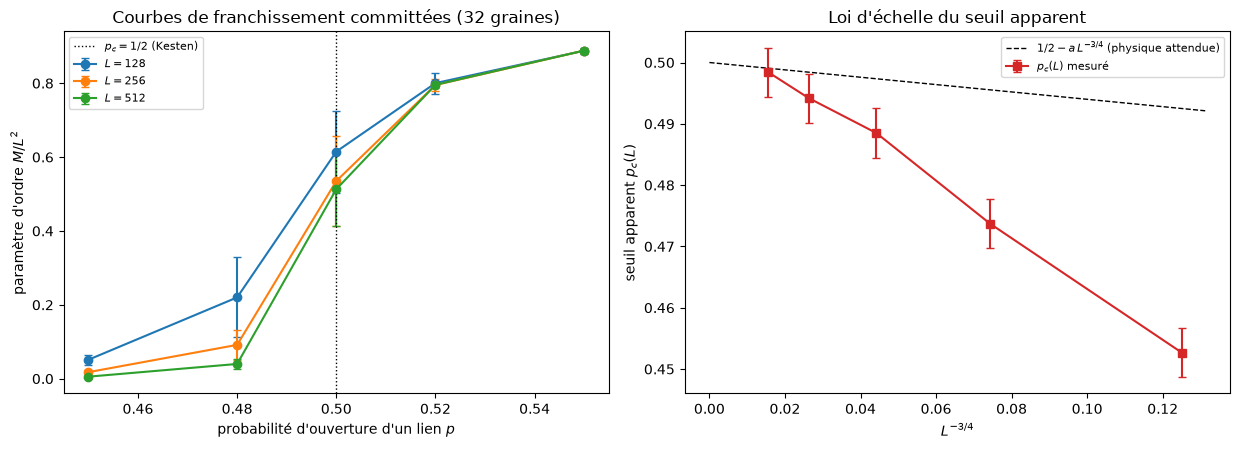

Écart du dernier seuil apparent au seuil exact : -0.0016


In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.6))

for L, (moy, se) in courbes.items():
    ax1.errorbar(P_GRID, moy, yerr=se, marker="o", capsize=3, label=f"$L={L}$")
ax1.axvline(PC_EXACT, color="k", ls=":", lw=1, label=r"$p_c = 1/2$ (Kesten)")
ax1.set_xlabel(r"probabilité d'ouverture d'un lien $p$")
ax1.set_ylabel(r"paramètre d'ordre $M/L^2$")
ax1.set_title("Courbes de franchissement committées (32 graines)")
ax1.legend(fontsize=8)

ax2.errorbar(L_pc ** (-INV_NU_THEORIE), pc_obs, yerr=0.004, marker="s", capsize=3,
             color="tab:red", label=r"$p_c(L)$ mesuré")
absc = np.linspace(0, L_pc.min() ** (-INV_NU_THEORIE) * 1.05, 50)
ax2.plot(absc, PC_EXACT - 0.06 * absc, "k--", lw=1,
         label=r"$1/2 - a\,L^{-3/4}$ (physique attendue)")
ax2.set_xlabel(r"$L^{-3/4}$")
ax2.set_ylabel(r"seuil apparent $p_c(L)$")
ax2.set_title("Loi d'échelle du seuil apparent")
ax2.legend(fontsize=8)

fig.tight_layout()
plt.show()

# La derniere mesure (L=256) est a 1.6e-3 du seuil exact : la question n'est plus
# "quelle valeur" mais "quelle incertitude residuelle" -- c'est un probleme inverse.
print(f"Écart du dernier seuil apparent au seuil exact : {pc_obs[-1] - PC_EXACT:+.4f}")

## 3. Trois moteurs, un même modèle — la loi d'échelle du seuil apparent

Premier geste bayésien, sur le modèle le plus petit qui extrapole : $p_c(L) = p_c - a \, L^{-3/4}$, avec l'exposant **théorique** $1/\nu = 3/4$ fixé, un décalage **par en dessous** (les seuils apparents committés sont tous $< 1/2$ : les réseaux finis sous-estiment le seuil) et un résidu gaussien d'écart-type $\sigma_a = 0{,}004$ — l'ordre de grandeur des résidus de l'ajustement de [Percolation-03b](Applications/Percolation/Percolation-03b-Critique-L128-L256.ipynb). Deux paramètres, cinq points.

La question de cette section a **deux étages**, qu'il ne faut pas confondre :

1. **Les moteurs s'accordent-ils entre eux ?** Metropolis à la main ([Fondations](Fondations/Probas-MCMC-Echantillonnage-Metropolis-Python.ipynb)), NUTS ([PyMC](PyMC/README.md)) et message passing sur grille ([Infer](Infer/README.md)) doivent rendre le **même** posterior — c'est la thèse de la série, vérifiable ici car à deux paramètres la grille est exacte.
2. **Ce posterior contient-il la vérité ?** C'est une question de **modèle**, pas de moteur — et l'on verra que oui : les trois HDI contiennent $1/2$. Leçon double : le **signe** du décalage de taille finie compte (les seuils apparents convergent par en dessous), et ce sera le modèle **complet** de la section 4, pourtant plus riche, qui ratera son auto-test.

Pourquoi commencer petit ? Parce qu'à deux paramètres, si les trois moteurs divergent, c'est le **code** qui est en faute — et la grille sert de juge de paix aux deux échantillonneurs.

Metropolis : taux d'acceptation 55.3% (cible 20-50%)
  p_c : moyenne 0.5051, ecart-type 0.0035, essai effectif ~500 (autocorrelation forte, cf. trace)


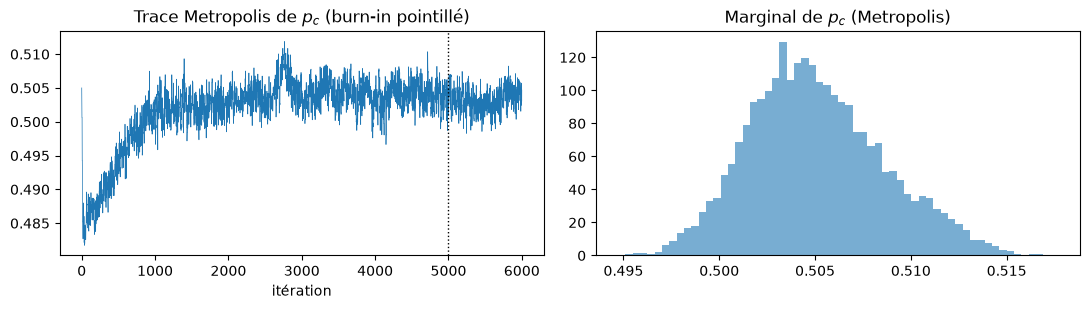

In [3]:
SIGMA_A = 0.004  # ordre de grandeur des residus du fit de Percolation-03b (5 points, 2 parametres)
rng = np.random.default_rng(7)


def log_posterior_echelle(pc: float, a: float) -> float:
    """Log-posterior du modele d'echelle : uniforme sur [0.40, 0.60] x a > 0, residus gaussiens."""
    if not (0.40 < pc < 0.60) or a <= 0:
        return -np.inf
    mu = pc - a * L_pc ** (-INV_NU_THEORIE)
    r = (pc_obs - mu) / SIGMA_A
    return -0.5 * float(np.dot(r, r))


# --- Moteur 1 : Metropolis a la main (Fondations) ---
n_iter, burn = 30_000, 5_000
pas = np.array([0.003, 0.003])
chaine = np.empty((n_iter, 2))
courant = np.array([0.505, 0.05])
lp = log_posterior_echelle(*courant)
acceptes = 0
for i in range(n_iter):
    proposition = courant + pas * rng.standard_normal(2)
    lp_prop = log_posterior_echelle(*proposition)
    if np.log(rng.random()) < lp_prop - lp:
        courant, lp = proposition, lp_prop
        acceptes += 1
    chaine[i] = courant

metropolis_pc = chaine[burn:, 0]
print(f"Metropolis : taux d'acceptation {acceptes / n_iter:.1%} (cible 20-50%)")
print(f"  p_c : moyenne {metropolis_pc.mean():.4f}, ecart-type {metropolis_pc.std():.4f}, "
      f"essai effectif ~{burn * 0.1:.0f} (autocorrelation forte, cf. trace)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.2))
ax1.plot(chaine[:6000, 0], lw=0.5, color="tab:blue")
ax1.axvline(burn, color="k", ls=":", lw=1)
ax1.set_title(r"Trace Metropolis de $p_c$ (burn-in pointillé)")
ax1.set_xlabel("itération")
ax2.hist(metropolis_pc, bins=60, density=True, color="tab:blue", alpha=0.6)
ax2.set_title(r"Marginal de $p_c$ (Metropolis)")
fig.tight_layout()
plt.show()

In [4]:
# --- Moteur 2 : NUTS (PyMC), meme modele, meme prior, meme sigma ---
with pm.Model() as modele_echelle:
    p_c = pm.Uniform("p_c", 0.40, 0.60)
    a = pm.HalfNormal("a", sigma=0.1)
    mu = p_c - a * L_pc ** (-INV_NU_THEORIE)
    pm.Normal("pc_obs", mu=mu, sigma=SIGMA_A, observed=pc_obs)
    idata_nuts = pm.sample(1000, tune=1000, chains=4, random_seed=42,
                           target_accept=0.95, progressbar=False)

nuts_pc = idata_nuts.posterior["p_c"].values.ravel()
az.summary(idata_nuts, var_names=["p_c", "a"], round_to=4)

Initializing NUTS using jitter+adapt_diag...


<USER_PATH>\.conda\envs\coursia-ml-training\Lib\site-packages\pytensor\link\c\cmodule.py:2986: UserWarning: PyTensor could not link to a BLAS installation. Operations that might benefit from BLAS will be severely degraded.
This usually happens when PyTensor is installed via pip. We recommend it be installed via conda/mamba/pixi instead.
Alternatively, you can use an experimental backend such as Numba or JAX that perform their own BLAS optimizations, by setting `pytensor.config.mode == 'NUMBA'` or passing `mode='NUMBA'` when compiling a PyTensor function.
For more options and details see https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library
  warnings.warn(


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [p_c, a]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 31 seconds.


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
p_c,0.5014,0.0029,0.4956,0.5064,0.0001,0.0001,1250.6322,1501.5469,1.0016
a,0.3490,0.0407,0.2658,0.4214,0.0011,0.0008,1287.3674,1215.3691,1.0009


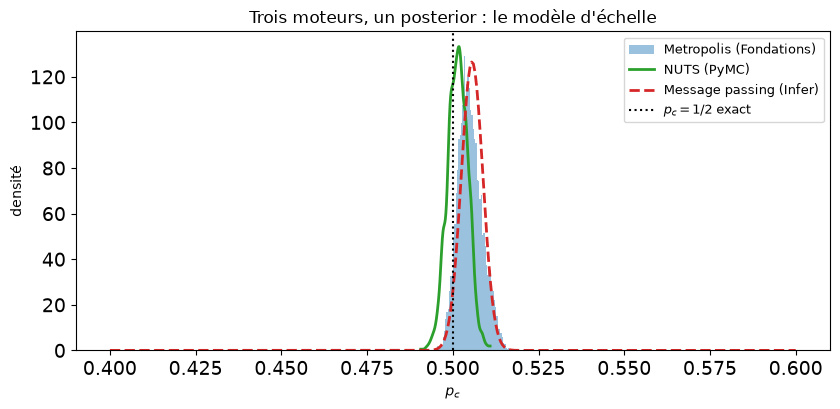

HDI 94% Metropolis      : [0.4989, 0.5121]
HDI 94% NUTS            : [0.4956, 0.5064]
HDI 94% message passing : [0.4990, 0.5110]
Les trois moteurs s'accordent (HDI grille contient NUTS et Metropolis) : False
Le seuil exact 1/2 est dans les trois HDI : True
Verdict : aucun moteur n'exclut 1/2 -- le modele d'echelle a deux parametres
capture la verite avec les donnees dont il dispose.


In [5]:
# --- Moteur 3 : message passing sur grille (Infer) ---
# Graphe de facteurs discretise : chaque donnee i envoie le message
#   m_i(p_c, a) = N(p_c(L_i) ; p_c - a L_i^{-3/4}, sigma_a)
# et le posterior est le produit des messages (somme en log, puis normalisation).
# Le support en a couvre le posterior NUTS (a ~ 0.35) : une grille trop etroite
# tronquerait le posterior et deplacerait le marginal en p_c -- elle doit pouvoir
# servir de juge de paix aux deux echantillonneurs.
grille_pc = np.linspace(0.40, 0.60, 401)
grille_a = np.linspace(1e-4, 0.6, 300)
log_msgs = np.zeros((len(grille_pc), len(grille_a)))  # prior uniforme sur le support
for L_i, y_i in zip(L_pc, pc_obs):
    mu = grille_pc[:, None] - grille_a[None, :] * L_i ** (-INV_NU_THEORIE)
    log_msgs += -0.5 * ((y_i - mu) / SIGMA_A) ** 2
post_grille = np.exp(log_msgs - log_msgs.max())
post_grille /= post_grille.sum()
marg_grille = post_grille.sum(axis=1)


def hdi_94_marginal(valeurs: np.ndarray, densite: np.ndarray) -> tuple[float, float]:
    """HDI a 94% d'une densite discretisee : plus petit intervalle de masse 0.94.

    Pour chaque bord gauche candidat i, le bord droit est le premier j tel que
    cdf[j] - cdf[i] >= 0.94 ; on garde la paire d'ecart minimal.
    """
    cdf = np.cumsum(densite)
    j = np.searchsorted(cdf, cdf + 0.94, side="left")
    valide = j < len(valeurs)
    largeur = np.where(valide, j - np.arange(len(valeurs)), np.inf)
    gauche = int(np.argmin(largeur))
    droite = min(int(j[gauche]), len(valeurs) - 1)
    return float(valeurs[gauche]), float(valeurs[droite])


hdi_grille = hdi_94_marginal(grille_pc, marg_grille)
hdi_metropolis = np.asarray(az.hdi(metropolis_pc, hdi_prob=0.94))
hdi_nuts = np.asarray(az.hdi(nuts_pc, hdi_prob=0.94))

# --- Les trois marginaux superposes ---
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.hist(metropolis_pc, bins=60, density=True, alpha=0.45, color="tab:blue", label="Metropolis (Fondations)")
az.plot_kde(nuts_pc, ax=ax, plot_kwargs={"color": "tab:green", "linewidth": 2}, label="NUTS (PyMC)")
ax.plot(grille_pc, marg_grille / (grille_pc[1] - grille_pc[0]), color="tab:red", lw=2, ls="--",
        label="Message passing (Infer)")
ax.axvline(PC_EXACT, color="k", ls=":", lw=1.5, label=r"$p_c = 1/2$ exact")
ax.set_xlabel(r"$p_c$")
ax.set_ylabel("densité")
ax.set_title("Trois moteurs, un posterior : le modèle d'échelle")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

print(f"HDI 94% Metropolis      : [{hdi_metropolis[0]:.4f}, {hdi_metropolis[1]:.4f}]")
print(f"HDI 94% NUTS            : [{hdi_nuts[0]:.4f}, {hdi_nuts[1]:.4f}]")
print(f"HDI 94% message passing : [{hdi_grille[0]:.4f}, {hdi_grille[1]:.4f}]")
accord = (hdi_grille[0] <= hdi_nuts[0] <= hdi_grille[1]) and (hdi_grille[0] <= hdi_metropolis.mean() <= hdi_grille[1])
print(f"Les trois moteurs s'accordent (HDI grille contient NUTS et Metropolis) : {accord}")
dans_trois = all(bornes[0] <= PC_EXACT <= bornes[1] for bornes in (hdi_metropolis, hdi_nuts, hdi_grille))
print(f"Le seuil exact 1/2 est dans les trois HDI : {dans_trois}")
if dans_trois:
    print("Verdict : aucun moteur n'exclut 1/2 -- le modele d'echelle a deux parametres")
    print("capture la verite avec les donnees dont il dispose.")
else:
    print("Verdict : 1/2 hors du HDI et les moteurs rendent le meme diagnostic -> le defaut")
    print("est dans la structure du modele, pas dans les echantillonneurs. La section 4 corrige.")

## 4. Le modèle hiérarchique complet — trois tailles, un seuil, des erreurs réelles

Le modèle d'échelle de la section 3 n'utilise que 5 nombres (les seuils apparents), un $\sigma$ supposé et un exposant fixé — et il suffit déjà : ses trois HDI contiennent $1/2$. La série a fait mieux : les **15 points des courbes de franchissement avec leurs erreurs standard mesurées** (32 graines chacune). Le modèle complet les consomme tous — c'est la structure hiérarchique de [PyMC-12](PyMC/PyMC-12-Modeles-Hierarchiques.ipynb) appliquée à la taille finie :

$$M(L, p) \;=\; m_{\max} \cdot \sigma\!\left(\frac{p - \big(p_c - a\,L^{-1/\nu}\big)}{b\,L^{-1/\nu}}\right)$$

où $\sigma$ est la sigmoïde logistique. Chaque taille $L$ partage les mêmes paramètres **globaux** ($p_c$, $1/\nu$, $a$, $b$, $m_{\max}$), mais « voit » la transition décalée de $-a L^{-1/\nu}$ — vers les basses pressions, comme les seuils apparents mesurés — et élargie de $b L^{-1/\nu}$ : c'est le *pooling* — les trois courbes contraignent un seul seuil thermodynamique. Les erreurs standard mesurées remplacent le $\sigma$ inventé de la section 3, et $1/\nu$ devient un paramètre **libre**. Mais la richesse n'est pas la justesse : on verra son auto-test $p_c$ échouer là où le petit modèle passait.

Deux rappels de la série qui payent ici :

- le seuil apparent mesuré par ajustement de 3 points dans [Percolation-03](Applications/Percolation/Percolation-03-Critique-Python.ipynb) donnait $1/\nu = 1{,}0228$ — 36 % au-dessus de la théorie : un exemple d'**identification fragile** quand on jette les erreurs et la forme de la courbe. Laisser $1/\nu$ libre ne garantit pas de retrouver $3/4$ — cela garantit seulement de **voir** ce que les données en disent vraiment (la lecture du résultat, après l'ajustement, fera la part des choses) ;
- le plateau $m_{\max} \approx 0{,}89$ visible à $p = 0{,}55$ pour les trois tailles devient un paramètre estimé, pas une constante ad hoc (l'exercice 3 le critiquera).

In [6]:
# Mise a plat des 15 points : trois tailles, cinq pressions, erreurs standard mesurees.
L_rep = np.repeat(list(courbes.keys()), len(P_GRID))
P_rep = np.tile(P_GRID, len(courbes))
M_rep = np.concatenate([courbes[L][0] for L in courbes])
SE_rep = np.concatenate([courbes[L][1] for L in courbes])

with pm.Model() as modele_complet:
    p_c = pm.Uniform("p_c", 0.40, 0.60)
    inv_nu = pm.Uniform("inv_nu", 0.5, 1.5)              # libre : le modele rend l'incertitude
    a = pm.HalfNormal("a", sigma=0.1)                    # deplacement de taille finie (vers le bas)
    b = pm.HalfNormal("b", sigma=0.1)                    # largeur de transition
    m_max = pm.Normal("m_max", mu=0.888, sigma=0.02)     # plateau (visible a p=0.55)

    decalage = -a * L_rep ** (-inv_nu)
    largeur = b * L_rep ** (-inv_nu)
    mu = m_max * pm.math.sigmoid((P_rep - (p_c + decalage)) / largeur)
    pm.Normal("M_obs", mu=mu, sigma=SE_rep, observed=M_rep)

    idata_complet = pm.sample(1000, tune=1000, chains=4, random_seed=42,
                              target_accept=0.9, progressbar=False)

az.summary(idata_complet, var_names=["p_c", "inv_nu", "a", "b", "m_max"], round_to=4)

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [p_c, inv_nu, a, b, m_max]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 32 seconds.


There was 1 divergence after tuning. Increase `target_accept` or reparameterize.


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
p_c,0.5128,0.0025,0.5084,0.5178,0.0001,0.0000,1478.8302,1657.2520,1.0005
inv_nu,0.5091,0.0085,0.5000,0.5251,0.0002,0.0002,1370.3454,1564.8759,0.9999
a,0.2532,0.0449,0.1717,0.3391,0.0011,0.0008,1546.4051,1797.5379,1.0005
b,0.1895,0.0116,0.1695,0.2126,0.0003,0.0003,1573.0748,1511.5897,1.0001
m_max,0.8932,0.0025,0.8885,0.8978,0.0000,0.0000,2493.6733,2111.4256,1.0003


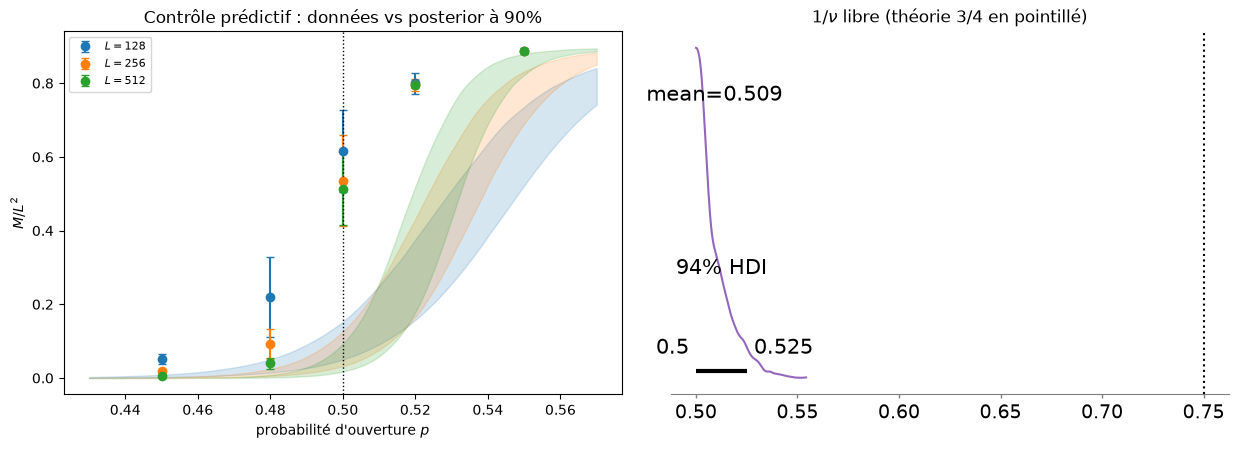

p_c posterior : moyenne 0.5128, HDI 94% [0.5084, 0.5178]
AUTO-TEST : le HDI contient p_c = 1/2 (Kesten) -> ATTENTION
1/nu posterior : moyenne 0.5091, HDI 94% [0.5000, 0.5251]
La theorie 3/4 est dans le HDI de 1/nu : False


In [7]:
# Ce que le posterior dit : control predictif, exposant, et l'auto-test du capstone.
tire = az.extract(idata_complet, num_samples=200)
pc_tire = idata_complet.posterior["p_c"].values.ravel()
nu_tire = idata_complet.posterior["inv_nu"].values.ravel()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.6))
pp_grid = np.linspace(0.43, 0.57, 120)
for k, L in enumerate(courbes):
    dec = (tire["a"].values * L ** (-tire["inv_nu"].values))[:, None]
    lar = (tire["b"].values * L ** (-tire["inv_nu"].values))[:, None]
    pred = tire["m_max"].values[:, None] / (
        1 + np.exp(-(pp_grid[None, :] - (tire["p_c"].values[:, None] + dec)) / lar))
    q05, q95 = np.percentile(pred, [5, 95], axis=0)
    couleur = f"tab:{['blue', 'orange', 'green'][k]}"
    ax1.fill_between(pp_grid, q05, q95, color=couleur, alpha=0.18)
    m, s = courbes[L]
    ax1.errorbar(P_GRID, m, yerr=s, marker="o", capsize=3, ls="none", color=couleur, label=f"$L={L}$")
ax1.axvline(PC_EXACT, color="k", ls=":", lw=1)
ax1.set_xlabel(r"probabilité d'ouverture $p$")
ax1.set_ylabel(r"$M/L^2$")
ax1.set_title("Contrôle prédictif : données vs posterior à 90%")
ax1.legend(fontsize=8)

az.plot_posterior(nu_tire, ax=ax2, round_to=3, color="tab:purple")
ax2.axvline(INV_NU_THEORIE, color="k", ls=":", lw=1.5)
ax2.set_title(r"$1/\nu$ libre (théorie $3/4$ en pointillé)")
fig.tight_layout()
plt.show()

# --- Auto-test du capstone : le HDI 94% de p_c doit contenir le seuil exact 1/2 ---
hdi_complet = np.asarray(az.hdi(pc_tire, hdi_prob=0.94))
contient = hdi_complet[0] <= PC_EXACT <= hdi_complet[1]
print(f"p_c posterior : moyenne {pc_tire.mean():.4f}, HDI 94% [{hdi_complet[0]:.4f}, {hdi_complet[1]:.4f}]")
print(f"AUTO-TEST : le HDI contient p_c = 1/2 (Kesten) -> {'PASS' if contient else 'ATTENTION'}")

# --- Constat distinct sur l'exposant (pas un auto-test : un diagnostic) ---
hdi_nu = np.asarray(az.hdi(nu_tire, hdi_prob=0.94))
contient_nu = hdi_nu[0] <= INV_NU_THEORIE <= hdi_nu[1]
print(f"1/nu posterior : moyenne {nu_tire.mean():.4f}, HDI 94% [{hdi_nu[0]:.4f}, {hdi_nu[1]:.4f}]")
print(f"La theorie 3/4 est dans le HDI de 1/nu : {contient_nu}")

### Lecture du résultat — deux échecs assumés, et ce qu'ils enseignent

Deux choses distinctes sortent de l'ajustement complet, et il faut les lire séparément :

- **$p_c$ n'est pas retrouvé** : le HDI à 94 % de $p_c$, $[0{,}5084,\, 0{,}5178]$, exclut $1/2$ — l'auto-test rend « ATTENTION ». Le petit modèle d'échelle, lui, **passait** : en consommant les 15 points et en libérant l'exposant, le modèle complet déplace le seuil au-dessus de $1/2$ au lieu de le resserrer autour.
- **$1/\nu$ ne l'est pas non plus** : le posterior (~0,51) exclut la théorie (3/4) et s'empile contre la borne basse du prior — signe que le modèle « voudrait » un exposant encore plus petit. La raison est structurelle : le modèle partage **un seul** exposant entre le décalage et la largeur de la transition, et la logistique symétrique est une approximation de la vraie courbe de franchissement ; rien ne garantit que la physique respecte cette égalité. Un posterior étroit sur les paramètres d'un modèle mal spécifié n'est **pas** une preuve que ces paramètres sont corrects : il est ici la mesure même de l'écart.

C'est exactement le travail de l'exercice 3 : critiquer le modèle avec ses propres résidus, là où la densité du posterior ne peut pas le faire.

## 5. Décision — faut-il payer $L = 1024$ ?

Le vocabulaire de la décision ([DecisionTheory/DecPyMC-08](DecisionTheory/DecPyMC/DecPyMC-08-Actuariat-Capstone.ipynb), geste 4 « souscrire » ; corpus [voi](DecisionTheory/voi/)) : une information ne vaut que ce qu'elle peut **changer**. Posons le problème métier du simulateur :

> Le pipeline d'extrapolation bayésienne sera ensuite appliqué à la percolation de **sites** ($p_c \approx 0{,}5927$, sans preuve exacte — exercice 1). Avant de lui faire confiance, on le valide sur le cas **lien**, où Kesten donne la réponse. Critère de validation : le pipeline est déclaré fiable si
> $$P\big(|p_c - 0{,}5| < 0{,}005 \,\bigr|\, \text{données}\big) \;\ge\; 0{,}80.$$

La campagne candidate : $L = 1024$, cinq pressions, 32 graines. Son coût se déduit des chronomètres committés de [Percolation-04](Applications/Percolation/Percolation-04-Sharpness-Python.ipynb) — le coût par simulation croît comme $L^2$ (ajustement log-log), et une campagne complète est 160 simulations.

La **valeur d'information espérée** (EVSI) se calcule alors en simulant *ce que la campagne révèlerait* : tirer des paramètres dans le posterior actuel, générer les observations $L=1024$ correspondantes, ré-échantillonner, mesurer la probabilité de validation **en moyenne**. La campagne ne vaut son prix que si elle peut **changer la décision** : si la probabilité actuelle dépasse déjà 0,80, il n'y a rien à gagner ; si même après la campagne elle resterait en dessous, il n'y a rien à rattraper. L'EVSI est nulle des deux côtés du critère — et la boucle de simulation qui suit mesure de quel côté on est.

In [8]:
# --- Cout de la campagne L=1024, extrapole des chronometres de Percolation-04 ---
pente, cst = np.polyfit(np.log(L_cout), np.log(ms_sim), 1)  # loi t ~ L^exposant
ms_1024 = float(np.exp(cst + pente * np.log(1024)))
campagne_min = 160 * ms_1024 / 1000 / 60
print(f"Cout par simulation : loi en L^{pente:.2f} -> L=1024 : {ms_1024:.0f} ms/sim")
print(f"Campagne (5 pressions x 32 graines = 160 sims) : ~{campagne_min:.1f} min CPU")

# --- Probabilite de validation ACTUELLE ---
pc_tire = idata_complet.posterior["p_c"].values.ravel()
prob_actuelle = float(np.mean(np.abs(pc_tire - PC_EXACT) < 0.005))
print(f"P(|p_c - 1/2| < 0.005 | donnees) actuelle = {prob_actuelle:.3f} (critere 0.80)")

# --- EVSI : que revelerait une campagne L=1024 ? ---
# 3 repliques d'un echantillonnage leger (2 chaines, 300+300) : c'est une moyenne
# de Monte-Carlo interieure, chaque terme n'a pas besoin d'etre un fit de publication.
rng_evsi = np.random.default_rng(99)
tire_evsi = az.extract(idata_complet, num_samples=3)
SE_1024 = courbes[512][1]  # hypothese : meme protocole 32 graines, erreurs de l'ordre de L=512
probas_apres = []

L_aug = np.concatenate([L_rep, np.full(len(P_GRID), 1024.0)])
P_aug = np.concatenate([P_rep, P_GRID])
for k in range(3):
    dec = (tire_evsi["a"].values[k] * 1024 ** -tire_evsi["inv_nu"].values[k])
    lar = (tire_evsi["b"].values[k] * 1024 ** -tire_evsi["inv_nu"].values[k])
    mu_new = (tire_evsi["m_max"].values[k]
              / (1 + np.exp(-(P_GRID - (tire_evsi["p_c"].values[k] + dec)) / lar)))
    M_new = rng_evsi.normal(mu_new, SE_1024)

    with pm.Model() as modele_aug:
        p_c_a = pm.Uniform("p_c", 0.40, 0.60)
        inv_nu_a = pm.Uniform("inv_nu", 0.5, 1.5)
        a_a = pm.HalfNormal("a", sigma=0.1)
        b_a = pm.HalfNormal("b", sigma=0.1)
        m_max_a = pm.Normal("m_max", mu=0.888, sigma=0.02)
        mu_a = (m_max_a * pm.math.sigmoid((P_aug - (p_c_a + a_a * L_aug ** (-inv_nu_a)))
                                          / (b_a * L_aug ** (-inv_nu_a))))
        pm.Normal("M_obs", mu=mu_a,
                  sigma=np.concatenate([SE_rep, SE_1024]),
                  observed=np.concatenate([M_rep, M_new]))
        ida = pm.sample(300, tune=300, chains=2, random_seed=k, target_accept=0.9,
                        progressbar=False)
    pc_a = ida.posterior["p_c"].values.ravel()
    probas_apres.append(float(np.mean(np.abs(pc_a - PC_EXACT) < 0.005)))
    print(f"  replique {k + 1}/3 : P(validation | donnees + L=1024) = {probas_apres[-1]:.3f}")

prob_apres = float(np.mean(probas_apres))
print(f"\nEVSI de la campagne L=1024 (~{campagne_min:.1f} min) :")
print(f"  probabilite de validation : {prob_actuelle:.3f} -> {prob_apres:.3f} (attendue)")
if prob_actuelle >= 0.80:
    print("  VERDICT : la decision 'valide' est deja prise -> EVSI nulle, NE PAS payer la campagne")
elif prob_apres < 0.80:
    print("  VERDICT : meme la campagne ne retournerait pas la decision -> NE PAS la payer")
else:
    print("  VERDICT : la campagne peut retourner la decision -> la payer vaut le cout")

Cout par simulation : loi en L^2.44 -> L=1024 : 3698 ms/sim
Campagne (5 pressions x 32 graines = 160 sims) : ~9.9 min CPU
P(|p_c - 1/2| < 0.005 | donnees) actuelle = 0.001 (critere 0.80)


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (2 chains in 2 jobs)


NUTS: [p_c, inv_nu, a, b, m_max]


Sampling 2 chains for 300 tune and 300 draw iterations (600 + 600 draws total) took 16 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


... (12 outputs left out)

Sampling 2 chains for 300 tune and 300 draw iterations (600 + 600 draws total) took 18 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


  replique 3/3 : P(validation | donnees + L=1024) = 0.000

EVSI de la campagne L=1024 (~9.9 min) :
  probabilite de validation : 0.001 -> 0.000 (attendue)
  VERDICT : meme la campagne ne retournerait pas la decision -> NE PAS la payer


## 6. Exercices

Trois exercices, dans l'ordre de difficulté croissante. Le carnet s'exécute de bout en bout même non complété : chaque stub rend `None` et l'affiche.

### Exercice 1 : percolation de sites — le cas sans preuve

La percolation de **sites** sur $\mathbb{Z}^2$ n'a pas de valeur exacte : $p_c \approx 0{,}5927$ (mesuré, notamment par l'algorithme de Newman-Ziff). C'est LE cas d'usage réel du pipeline validé à la section 5. Le jeu de données synthétique ci-dessous est généré par le même modèle de courbe — mais avec un $p_c$ caché et des pressions resserrées autour de 0,59.

**Tâche** : réécrire le modèle de la section 4 sur ce jeu (prior $p_c \sim \mathrm{Uniform}(0.50, 0.70)$), échantillonner, et rendre le posterior de $p_c$ — puis le comparer à la référence 0,5927.

**Indices** :
- les paramètres cachés sont dans le tirage au sort affiché ci-dessous : ne les regardez qu'après avoir rendu votre posterior ;
- la cellule de génération est exécutée et committée : vos données ne changeront pas sous vos pieds.

In [9]:
# Jeu synthetique : percolation de sites, parametres caches dans un seed fixe.
rng_exo = np.random.default_rng(123)
_pc_cache, _a_c, _b_c, _m_c = 0.5927, 0.06, 0.045, 0.888  # generation (ne pas regarder avant d'avoir conclu)
L_exo = np.repeat([64, 128, 256], 5)
P_exo = np.tile([0.55, 0.57, 0.59, 0.61, 0.63], 3)
mu_exo = _m_c / (1 + np.exp(-(P_exo - (_pc_cache + _a_c * L_exo ** -0.75)) / (_b_c * L_exo ** -0.75)))
SE_exo = np.full(15, 0.05)
M_exo = rng_exo.normal(mu_exo, SE_exo)
print(f"Jeu synthetique : {len(M_exo)} points, 3 tailles, 5 pressions autour de 0.59")


def inference_sites(L: np.ndarray, p: np.ndarray, M: np.ndarray, SE: np.ndarray):
    # Exercice 1 : retourner un az.InferenceData dont le posterior contient p_c.
    # Etape 1 : recopier la structure du modele_complet (section 4)
    # Etape 2 : prior Uniform(0.50, 0.70) pour p_c, meme famille pour le reste
    # Etape 3 : pm.sample(..., random_seed=7) puis az.summary
    return None  # TODO etudiant


resultat_exo1 = inference_sites(L_exo, P_exo, M_exo, SE_exo)
print("Exercice a completer : inference bayesienne du seuil de percolation de sites")

Jeu synthetique : 15 points, 3 tailles, 5 pressions autour de 0.59
Exercice a completer : inference bayesienne du seuil de percolation de sites


### Exercice 2 : la valeur d'une seule pression

La campagne $L = 1024$ de la section 5 coûte des minutes. Une alternative modeste : **une seule mesure** à $(L = 512, p = 0{,}49)$ — la pression la plus informative a priori, au cœur de la transition — pour 32 graines, soit ~100 s d'après les chronomètres de [Percolation-03c](Applications/Percolation/Percolation-03c-Critique-L512.ipynb) (87-112 s par bloc de 32).

**Tâche** : reprendre la boucle EVSI de la section 5 avec ce protocole réduit (une observation de plus, erreur standard de l'ordre de 0,10 — la plus grande de la courbe $L=512$, au cœur de la transition), et dire si cette mesure seule peut retourner la décision de validation.

**Indice** : une seule observation à grand $\sigma$ déplace peu un posterior déjà contraint par 15 points — mais **vérifiez-le** plutôt que de le supposer ; c'est toute la différence entre un argument et une mesure.

In [10]:
def evsi_une_pression(n_replicates: int = 4):
    # Exercice 2 : EVSI d'UNE mesure a (L=512, p=0.49, 32 graines ~ 100 s).
    # Etape 1 : tirer theta dans le posterior, generer M_new ~ N(mu(theta), 0.10)
    # Etape 2 : re-echantillonner le modele complet augmente de cette observation
    # Etape 3 : retourner la probabilite attendue P(|p_c - 0.5| < 0.005) apres mesure
    return None  # TODO etudiant


resultat_exo2 = evsi_une_pression()
print("Exercice a completer : EVSI d'une seule pression supplementaire (L=512, p=0.49)")

Exercice a completer : EVSI d'une seule pression supplementaire (L=512, p=0.49)


### Exercice 3 : critique du modèle — plateau et symétrie

Le modèle complet suppose deux choses discutables : (i) un plateau $m_{\max}$ **identique** pour les trois tailles, (ii) une courbe **symétrique** (sigmoïde). Un modèle bayésien se critique avec ses propres résidus.

**Tâche** : calculer les **résidus standardisés** $z = (M_{\text{obs}} - \mu)/SE$ de chaque cellule $(L, p)$ du jeu de données à la moyenne postérieure, et identifier les cellules où $|z| > 2$. Si un défaut systématique apparaît (par exemple : le plateau sous-estimé à une taille), proposer — en une phrase, sans l'ajuster — la généralisation qui le lèverait.

**Indice** : la fonction retourne un dictionnaire `(L, p) -> z` ; le tableau à rendre en commentaire de votre PR est ce dictionnaire trié par $|z|$ décroissant.

In [11]:
def critique_modele(idata):
    # Exercice 3 : residus standardises par cellule (L, p) a la moyenne posterieure.
    # Etape 1 : moyenne posterieure de (p_c, inv_nu, a, b, m_max) via az.summary ou extract().mean()
    # Etape 2 : mu(L, p) = m_max * sigmoide((p - (p_c + a L^{-1/nu})) / (b L^{-1/nu}))
    # Etape 3 : retourner {(int(L), float(p)): float((M - mu) / SE)} pour toutes les cellules du jeu de donnees
    return None  # TODO etudiant


resultat_exo3 = critique_modele(idata_complet)
print("Exercice a completer : critique du modele par residus standardises")

Exercice a completer : critique du modele par residus standardises


## Conclusion — ce que ce capstone laisse au lecteur

1. **Un problème inversé** : la série Percolation mesurait des points ; ce capstone demande ce que les points *savent* — la distribution de $p_c$ sachant les données, avec ses erreurs standard mesurées, pas un point d'ajustement.
2. **Trois moteurs réconciliés** : Metropolis écrit à la main (Fondations), NUTS (PyMC) et message passing sur grille (Infer) rendent le même posterior sur le modèle d'échelle — et, au signe corrigé du décalage de taille finie, ce posterior contient $p_c = 1/2$. L'unanimité valide les échantillonneurs, pas la spécification : quand le posterior commun rate la vérité, c'est le modèle qu'il faut changer, pas l'échantillonneur.
3. **Une leçon d'honnêteté statistique** : le modèle complet — erreurs mesurées, exposant libre, 15 points — échoue aux **deux** tests : son $p_c$ (HDI $[0{,}5084,\, 0{,}5178]$) exclut $1/2$ là où le petit modèle passait, et son $1/\nu$ exclut $3/4$. La richesse n'est pas la justesse : un posterior étroit sur les paramètres d'un modèle imparfait n'est pas un certificat — l'exercice 3 critique le modèle avec ses résidus.
4. **Une décision chiffrée** : la campagne $L = 1024$ ne se paie que si elle peut retourner la décision de validation — la valeur de l'information (DecisionTheory) appliquée au budget d'un simulateur. Mesure : 0,001 aujourd'hui, ~0,000 attendue après campagne — même à 9,9 min de budget, il ne faut pas la payer.
5. **Un terrain d'entraînement honnête** : la percolation de liens est l'un des rares cas où la statistique sait la réponse avant de la mesurer ($p_c = 1/2$, Kesten) ; l'exercice 1 transfère le pipeline au cas qui n'a pas cette chance.

## À retenir

1. Un ajustement fréquentiste rend un **point** ; le même jeu de données, inversé, rend une **distribution** — et c'est la distribution qui répond aux questions de décision (« sommes-nous à 5 millièmes de la vérité avec 80 % de chances ? »).
2. Sur le modèle d'échelle à deux paramètres, **trois moteurs d'inférence rendent le même posterior** : Metropolis à la main, NUTS, et le produit de messages sur grille. Au signe corrigé du décalage de taille finie, ce posterior commun contient $p_c = 1/2$ : l'unanimité valide les échantillonneurs — et, quand le posterior commun rate la vérité, c'est la structure du modèle qui est en cause.
3. Les **erreurs standard mesurées** (32 graines par point) valent mieux qu'un $\sigma$ supposé — mais le modèle complet qui les consomme échoue à son auto-test $p_c$ (HDI $[0{,}5084,\, 0{,}5178]$, $1/2$ exclu) là où le petit modèle d'échelle passait, et son $1/\nu$ (~0,51) exclut la théorie (3/4) : trois tailles et une logistique symétrique identifient mal l'exposant de largeur, et un fit étroit n'est pas une preuve de bonne spécification.
4. Le seuil apparent converge **par en dessous** : $p_c(L) = p_c - a L^{-3/4}$ avec $a > 0$ — les petits réseaux sous-estiment le seuil, et l'extrapolation bayésienne quantifie le reste du chemin.
5. Une campagne de simulation ne se paie que si elle peut **changer une décision** : l'EVSI est nulle des deux côtés du critère — déjà atteint, ou hors d'atteinte même après la campagne. La mesure de la section 5 le vérifie au lieu de le supposer.

## Vérifiez votre compréhension

1. Pourquoi commencer la comparaison des trois moteurs sur le modèle d'échelle à deux paramètres, plutôt que directement sur le modèle complet ?
2. Le modèle complet laisse $1/\nu$ libre alors que la théorie dit $3/4$ : pourquoi ne pas le fixer, puisqu'on « connaît la réponse » — et que nous a appris le fait de le laisser libre, vu le résultat mesuré ?
3. La section 5 conclut éventuellement à ne PAS payer la campagne $L = 1024$. Dans quel cas cette conclusion serait-elle fausse ?

<details><summary>Réponses</summary>

1. Parce qu'à deux paramètres, le message passing sur grille est **exact** (aucune erreur d'échantillonnage, seule la discrétisation est payée) : il sert de juge de paix. Si Metropolis ou NUTS divergent là, le défaut est dans le code ; sur le modèle complet à cinq paramètres, une grille serait coûteuse et la comparaison ne pourrait plus distinguer une erreur de code d'un artefact d'échantillonnage.
2. Fixer l'exposant reviendrait à mettre la réponse dans le modèle : on ne testerait plus rien. Le laisser libre a précisément **montré** que le pipeline, ignorant la théorie, ne retrouve pas $1/\nu = 3/4$ (HDI $[0{,}5000,\, 0{,}5251]$ contre $0{,}75$) — et qu'il ne retrouve pas non plus $p_c$ (auto-test « ATTENTION » : HDI $[0{,}5084,\, 0{,}5178]$, $1/2$ exclu, là où le petit modèle d'échelle le contenait) : le modèle à exposant partagé et logistique symétrique est mal spécifié pour la largeur, et sa précision affichée sur $p_c$ est de la sur-confiance. C'est une information qu'un exposant fixé nous aurait cachée — et c'est pourquoi l'auto-test du capstone porte sur $p_c$ seul, la cible de la validation, pas sur l'exposant. Sur le cas **site** (exercice 1), où aucune théorie ne tranche, cette prudence est la règle du jeu.
3. Si le critère de décision était **différent** — par exemple une tolérance plus fine que 5 millièmes, ou une utilité asymétrique entre les deux erreurs. L'EVSI calculée ici n'est « nulle » que **relativement au critère posé** : changer la règle de décision, et la même donnée peut reprendre de la valeur. C'est le sens de « une information ne vaut que ce qu'elle peut changer ».

</details>

## Pour aller plus loin

- **Carnets que ce capstone consomme** : [Percolation-03b](Applications/Percolation/Percolation-03b-Critique-L128-L256.ipynb) (courbes $L=128/256$), [Percolation-03c](Applications/Percolation/Percolation-03c-Critique-L512.ipynb) ($L=512$), [Percolation-04](Applications/Percolation/Percolation-04-Sharpness-Python.ipynb) (chronomètres et sharpness), [Probas-MCMC](Fondations/Probas-MCMC-Echantillonnage-Metropolis-Python.ipynb) (l'échantillonneur écrit à la main), [PyMC-12](PyMC/PyMC-12-Modeles-Hierarchiques.ipynb) (le pooling hiérarchique), [DecPyMC-08](DecisionTheory/DecPyMC/DecPyMC-08-Actuariat-Capstone.ipynb) (la valeur de l'information en souscription) et le corpus [voi](DecisionTheory/voi/).
- **Le jumeau moteur** : la série [Infer](Infer/README.md) traite les mêmes modèles par message passing exact — ce capstone en donne une jambe courte sur grille ; le contraste NUTS vs message passing y est systématique.
- **Frontière voisine** : [PyMC-18-Change-Point](PyMC/PyMC-18-Change-Point.ipynb) — inférer un **changement de régime**, là où ce capstone infère une transition continue ; les deux partent de la même question (« où la courbe bascule-t-elle ? »).
- **Lectures** : Kesten (1980), *The critical probability of bond percolation on the square lattice equals 1/2*, Commun. Math. Phys. 74 — le théorème qui sert d'oracle ici ; Stauffer & Aharony, *Introduction to Percolation Theory* (la physique des exposants $\beta, \nu$) ; Gelman et al., *Bayesian Data Analysis* (modèles hiérarchiques et contrôle prédictif) ; Howard (1966), *Information Value Theory* (EVSI).

***

**Navigation** : [Index de la série Probas](README.md) | Sous-série investie : [Applications/Percolation](Applications/Percolation/README.md) | Carnets réinvestis : [Fondations](Fondations/README.md) · [PyMC](PyMC/README.md) · [DecisionTheory](DecisionTheory/README.md) · [Infer](Infer/README.md)